# T21 — Classifieur de genre

Le classifieur prédit la **famille de genre** d'un morceau (taxonomie v1, `indexer/genre_map.yaml`) à partir de ses **embeddings audio** : un vecteur par segment de 10 s, calculé par le modèle choisi en T18. La prédiction d'un morceau est la moyenne des probabilités de ses segments.

**Protocole** :
- **Validation croisée en 5 plis, groupée par artiste et stratifiée par classe.** Un artiste n'est jamais à la fois dans l'entraînement et dans le test : sinon le modèle reconnaîtrait la voix ou le son de l'artiste plutôt que le genre (T18 a montré l'effet). Avec ~250 morceaux, une seule séparation entraînement / test serait trop bruitée.
- **Les classes de moins de `MIN_SONGS` morceaux sont mises de côté** : on ne peut ni les apprendre ni les évaluer sérieusement.
- **Deux modèles** : une **régression logistique** (référence, `C` choisi par validation croisée interne) et un **petit MLP** PyTorch (une couche cachée, dropout, arrêt précoce sur une validation interne groupée par artiste). Les deux ont des poids de classe, car les classes sont déséquilibrées.
- **Métriques** : **F1 macro** au niveau du morceau (chaque classe pèse autant), précision, matrice de confusion.
- **Règle fixée avant les résultats** : on garde le MLP seulement s'il a un F1 macro moyen plus élevé **et** gagne sur au moins 4 plis sur 5. Sinon on garde la régression logistique, plus simple et plus stable.
- **Comparaison** : même protocole sur un sous-ensemble équilibré de **FMA-small**, un jeu de référence public (8 genres, extraits de 30 s), pour situer les chiffres.

**Lancer sur Colab** : *Exécution → Tout exécuter*. La cellule suivante installe le code du projet depuis GitHub, puis demande le fichier `genre_dataset.npz`, produit en local par `python -m indexer export-genre-data`. Ce fichier ne contient aucun audio, seulement des vecteurs, des identifiants, les artistes et les classes.

In [1]:
import os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # the project's code (same embedding recipe as the indexer) + partial zip reads
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "earworm @ git+https://github.com/romeobergamasco/earworm", "remotezip"])

EMBED_MODEL = os.environ.get("EARWORM_EMBED_MODEL", "clap-htsat-unfused")
MIN_SONGS = 8      # smaller classes are set aside
N_FOLDS = 5
SEED = 0
RUN_FMA = os.environ.get("EARWORM_RUN_FMA", "1") == "1"
FMA_PER_GENRE = int(os.environ.get("EARWORM_FMA_PER_GENRE", "50"))
FORCE_MODEL = os.environ.get("EARWORM_FORCE_MODEL")  # tests only: "mlp" or "logreg"
print("Colab" if IN_COLAB else "local", "| embedding:", EMBED_MODEL)

local | embedding: clap-htsat-unfused


In [2]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

if IN_COLAB:
    from google.colab import files
    DATA = Path(next(iter(files.upload())))  # genre_dataset.npz
    WORK = Path("/content/earworm_work")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA = Path(os.environ.get("EARWORM_GENRE_DATA", ROOT / "data" / "genre_dataset.npz"))
    WORK = ROOT / "data" / "t21"
WORK.mkdir(parents=True, exist_ok=True)

d = np.load(DATA, allow_pickle=False)
meta = json.loads(str(d["meta"]))
assert meta["model"] == EMBED_MODEL, f"dataset made with {meta['model']}"
X_seg = d["X"].astype(np.float32)
if X_seg.ndim == 3:  # MERT: (segments, layers, dim) -> mean of the layers (T18)
    X_seg = X_seg.mean(axis=1)
seg_song, seg_label, seg_artist = d["song_id"], d["label"], d["artist"]
names = meta["classes"]
print(f"{len(X_seg)} segments, {len(set(seg_song))} songs, dim {X_seg.shape[1]}, taxonomy v{meta['taxonomy_version']}")

1511 segments, 269 songs, dim 512, taxonomy v1


## Classes retenues

In [3]:
songs = np.array(sorted(set(seg_song.tolist())))
first = {s: i for i, s in reversed(list(enumerate(seg_song)))}
song_label = np.array([seg_label[first[s]] for s in songs])
song_artist = np.array([seg_artist[first[s]] for s in songs])
counts = Counter(l for l in song_label if l)
kept = sorted(c for c, n in counts.items() if n >= MIN_SONGS)
print("| classe | morceaux | retenue |\n|---|---|---|")
for c, n in counts.most_common():
    print(f"| {names.get(c, c)} | {n} | {'oui' if c in kept else 'non (< %d)' % MIN_SONGS} |")
print(f"sans classe : {(song_label == '').sum()} morceaux (prédits plus tard, pas évalués)")

use = np.isin(song_label, kept)
S, y_song, g_song = songs[use], song_label[use], song_artist[use]
classes = np.array(kept)
print(f"\n{len(S)} morceaux, {len(set(g_song))} artistes, {len(classes)} classes")

| classe | morceaux | retenue |
|---|---|---|
| Rock | 73 | oui |
| Électro / dance | 54 | oui |
| R&B / soul / funk | 35 | oui |
| Pop | 29 | oui |
| Hip-hop / rap | 26 | oui |
| Chanson / variété française | 15 | oui |
| Country / folk | 15 | oui |
| Jazz / blues | 14 | oui |
| Latino | 6 | non (< 8) |
| Reggae / Caraïbes | 2 | non (< 8) |
sans classe : 0 morceaux (prédits plus tard, pas évalués)

261 morceaux, 235 artistes, 8 classes


## Modèles

In [4]:
def segments_of(song_ids, seg_song=None, X=None):
    seg_song = globals()["seg_song"] if seg_song is None else seg_song
    X = X_seg if X is None else X
    m = np.isin(seg_song, song_ids)
    return X[m], seg_song[m]


def song_probas(model, Xs, ss, song_ids):
    """Mean of the segment probabilities of each song."""
    P = model.predict_proba(Xs)
    return np.stack([P[ss == s].mean(axis=0) for s in song_ids])


class LogReg:
    """Standardised logistic regression, C chosen by an inner artist-grouped CV."""

    def __init__(self, Cs=(0.01, 0.1, 1.0)):
        self.Cs = Cs

    def _make(self, C):
        return make_pipeline(StandardScaler(), LogisticRegression(
            C=C, max_iter=5000, class_weight="balanced"))

    def fit(self, X, y, groups):
        best = None
        for C in self.Cs:
            scores = []
            for tr, va in StratifiedGroupKFold(3, shuffle=True, random_state=SEED).split(X, y, groups):
                m = self._make(C).fit(X[tr], y[tr])
                scores.append(f1_score(y[va], m.predict(X[va]), average="macro", zero_division=0))
            if best is None or np.mean(scores) > best[0]:
                best = (np.mean(scores), C)
        self.C = best[1]
        self.model = self._make(self.C).fit(X, y)
        self.classes_ = self.model.classes_
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def export(self):
        sc, lr = self.model[0], self.model[1]
        return {"kind": "logreg", "mean": sc.mean_, "scale": sc.scale_,
                "W": [lr.coef_.T], "b": [lr.intercept_], "C": self.C}


class MLP:
    """One hidden layer (ReLU, dropout), class-weighted cross-entropy, AdamW,
    early stopping on an inner validation split grouped by artist."""

    def __init__(self, hidden=256, dropout=0.3, lr=1e-3, wd=1e-2, epochs=300, patience=25):
        self.h, self.p, self.lr, self.wd, self.epochs, self.patience = hidden, dropout, lr, wd, epochs, patience

    def fit(self, X, y, groups):
        torch.manual_seed(SEED)
        self.classes_ = np.unique(y)
        yi = np.searchsorted(self.classes_, y)
        self.mean, self.scale = X.mean(0), X.std(0) + 1e-6
        Z = torch.tensor((X - self.mean) / self.scale, dtype=torch.float32)
        T = torch.tensor(yi)
        tr, va = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(X, y, groups))
        w = torch.tensor(len(yi) / (len(self.classes_) * np.bincount(yi, minlength=len(self.classes_)).clip(1)),
                         dtype=torch.float32)
        self.net = torch.nn.Sequential(torch.nn.Linear(X.shape[1], self.h), torch.nn.ReLU(),
                                       torch.nn.Dropout(self.p), torch.nn.Linear(self.h, len(self.classes_)))
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=self.wd)
        loss_fn = torch.nn.CrossEntropyLoss(weight=w)
        best, best_state, wait = np.inf, None, 0
        g = torch.Generator().manual_seed(SEED)
        for epoch in range(self.epochs):
            self.net.train()
            for idx in torch.randperm(len(tr), generator=g).split(64):
                b = torch.as_tensor(tr)[idx]
                opt.zero_grad()
                loss_fn(self.net(Z[b]), T[b]).backward()
                opt.step()
            self.net.eval()
            with torch.no_grad():
                v = loss_fn(self.net(Z[va]), T[va]).item()
            if v < best - 1e-4:
                best, wait = v, 0
                best_state = {k: t.clone() for k, t in self.net.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net.load_state_dict(best_state)
        self.epochs_run = epoch + 1
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            z = torch.tensor((X - self.mean) / self.scale, dtype=torch.float32)
            return torch.softmax(self.net(z), dim=1).numpy()

    def export(self):
        l1, l2 = self.net[0], self.net[3]
        return {"kind": "mlp", "mean": self.mean, "scale": self.scale,
                "W": [l1.weight.detach().numpy().T, l2.weight.detach().numpy().T],
                "b": [l1.bias.detach().numpy(), l2.bias.detach().numpy()]}

In [5]:
def cross_validate(make, S, y_song, g_song, seg_song_all, X_all, label=""):
    """Artist-grouped, class-stratified K-fold at the song level."""
    folds, y_true, y_pred = [], [], []
    for k, (tr, te) in enumerate(StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(S, y_song, g_song)):
        Xtr, str_ = segments_of(S[tr], seg_song_all, X_all)
        lab = dict(zip(S, y_song)); art = dict(zip(S, g_song))
        model = make().fit(Xtr, np.array([lab[s] for s in str_]), np.array([art[s] for s in str_]))
        Xte, ste = segments_of(S[te], seg_song_all, X_all)
        P = song_probas(model, Xte, ste, S[te])
        pred = model.classes_[P.argmax(1)]
        folds.append({"f1_macro": f1_score(y_song[te], pred, average="macro", labels=np.unique(y_song), zero_division=0),
                      "accuracy": accuracy_score(y_song[te], pred)})
        y_true += list(y_song[te]); y_pred += list(pred)
    f1s = [f["f1_macro"] for f in folds]
    print(f"{label:22s} F1 macro {np.mean(f1s):.3f} ± {np.std(f1s):.3f}   précision {np.mean([f['accuracy'] for f in folds]):.3f}")
    return {"folds": folds, "y_true": np.array(y_true), "y_pred": np.array(y_pred)}


def baselines(y_song):
    rng = np.random.default_rng(SEED)
    major = Counter(y_song).most_common(1)[0][0]
    f1_major = f1_score(y_song, [major] * len(y_song), average="macro")
    f1_rand = np.mean([f1_score(y_song, rng.permutation(y_song), average="macro") for _ in range(200)])
    print(f"{'hasard (proportions)':22s} F1 macro {f1_rand:.3f}")
    print(f"{'classe majoritaire':22s} F1 macro {f1_major:.3f}   précision {Counter(y_song)[major] / len(y_song):.3f}")
    return f1_rand, f1_major

## Résultats sur le catalogue Earworm

In [6]:
base = baselines(y_song)
res_lr = cross_validate(LogReg, S, y_song, g_song, seg_song, X_seg, "régression logistique")
res_mlp = cross_validate(MLP, S, y_song, g_song, seg_song, X_seg, "MLP")
f_lr = np.array([f["f1_macro"] for f in res_lr["folds"]])
f_mlp = np.array([f["f1_macro"] for f in res_mlp["folds"]])
wins = int((f_mlp > f_lr).sum())
keep_mlp = f_mlp.mean() > f_lr.mean() and wins >= 4
if FORCE_MODEL:  # tests of the export path only
    keep_mlp = FORCE_MODEL == "mlp"
    print("(choix forcé pour un test :", FORCE_MODEL, ")")
print(f"\nMLP − régression : {f_mlp.mean() - f_lr.mean():+.3f} de F1 macro, MLP meilleur sur {wins}/{N_FOLDS} plis")
print("→ modèle retenu :", "MLP" if keep_mlp else "régression logistique")

hasard (proportions)   F1 macro 0.125
classe majoritaire     F1 macro 0.055   précision 0.280


régression logistique  F1 macro 0.407 ± 0.061   précision 0.441


MLP                    F1 macro 0.388 ± 0.071   précision 0.437

MLP − régression : -0.019 de F1 macro, MLP meilleur sur 2/5 plis
→ modèle retenu : régression logistique


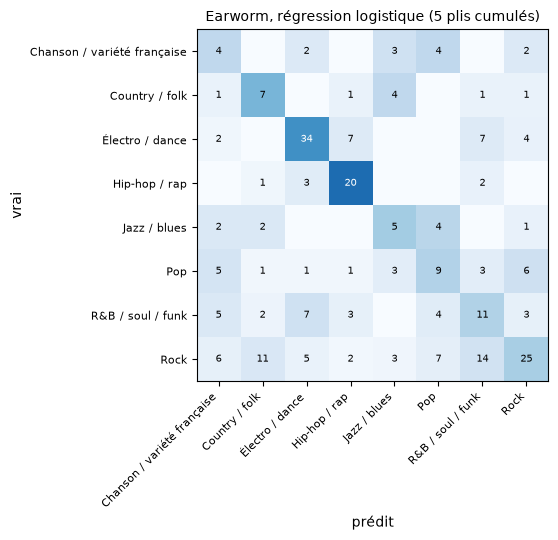

Chanson / variété française 0.20 | Country / folk 0.36 | Électro / dance 0.64 | Hip-hop / rap 0.67 | Jazz / blues 0.31 | Pop 0.32 | R&B / soul / funk 0.30 | Rock 0.43


In [7]:
def show_confusion(res, title):
    labels = classes
    cm = confusion_matrix(res["y_true"], res["y_pred"], labels=labels)
    cmn = cm / cm.sum(1, keepdims=True).clip(1)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), [names.get(c, c) for c in labels], rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels)), [names.get(c, c) for c in labels], fontsize=8)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                        color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xlabel("prédit"); ax.set_ylabel("vrai"); ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.show()
    f1c = f1_score(res["y_true"], res["y_pred"], labels=labels, average=None)
    print(" | ".join(f"{names.get(c, c)} {f:.2f}" for c, f in zip(labels, f1c)))

chosen = res_mlp if keep_mlp else res_lr
show_confusion(chosen, "Earworm, " + ("MLP" if keep_mlp else "régression logistique") + " (5 plis cumulés)")

## Comparaison : FMA-small

[FMA](https://github.com/mdeff/fma) (*Free Music Archive*) est un jeu public de morceaux sous licence libre. Sa partie *small* contient 8 genres équilibrés d'extraits de 30 s. On en prend `FMA_PER_GENRE` par genre, en téléchargeant **uniquement ces fichiers** dans l'archive (lecture partielle du zip). On calcule leurs embeddings avec **exactement la même recette** que l'indexeur (`earworm.embeddings`), puis on efface l'audio et on applique le même protocole (plis groupés par artiste).

In [8]:
def fma_embeddings():
    """Segment embeddings of FMA_PER_GENRE clips per genre (indexer/fma.py), cached."""
    cache = WORK / f"fma_{EMBED_MODEL}_{FMA_PER_GENRE}.npz"
    if cache.exists():
        with np.load(cache) as z:
            return {k: z[k] for k in z}
    from earworm.embeddings import ClapEmbedder, MertEmbedder, embed_segments
    from indexer.fma import clips, sample

    tracks = sample(FMA_PER_GENRE, WORK, seed=SEED)
    embedder = {"clap-htsat-unfused": ClapEmbedder, "mert-v1-95m": MertEmbedder}[EMBED_MODEL]()
    X, tid, genre, artist = [], [], [], []
    for n, (t, path) in enumerate(clips(tracks), 1):
        try:
            v = embed_segments(path, embedder)  # the clip is deleted right after
        except Exception as e:  # a few FMA files are corrupt
            print("skip", t.track_id, type(e).__name__)
            continue
        v = v.mean(axis=1) if v.ndim == 3 else v
        X.append(v)
        tid += [t.track_id] * len(v); genre += [t.genre] * len(v); artist += [t.artist] * len(v)
        if n % 50 == 0:
            print(f"{n}/{len(tracks)}")
    out = {"X": np.concatenate(X).astype(np.float32), "song_id": np.array(tid),
           "label": np.array(genre), "artist": np.array(artist)}
    np.savez(cache, **out)
    return out

if RUN_FMA:
    f = fma_embeddings()
    fS = np.array(sorted(set(f["song_id"].tolist())))
    ff = {s: i for i, s in reversed(list(enumerate(f["song_id"])))}
    fy = np.array([f["label"][ff[s]] for s in fS]); fg = np.array([f["artist"][ff[s]] for s in fS])
    print(f"FMA : {len(fS)} extraits, {len(set(fg))} artistes, genres {dict(Counter(fy))}")
    fma_base = baselines(fy)
    fma_lr = cross_validate(LogReg, fS, fy, fg, f["song_id"], f["X"], "régression logistique")
    fma_mlp = cross_validate(MLP, fS, fy, fg, f["song_id"], f["X"], "MLP")

FMA : 400 extraits, 319 artistes, genres {np.str_('Folk'): 50, np.str_('Rock'): 50, np.str_('Experimental'): 50, np.str_('International'): 50, np.str_('Electronic'): 50, np.str_('Hip-Hop'): 50, np.str_('Pop'): 50, np.str_('Instrumental'): 50}


hasard (proportions)   F1 macro 0.125
classe majoritaire     F1 macro 0.028   précision 0.125


régression logistique  F1 macro 0.555 ± 0.020   précision 0.560


MLP                    F1 macro 0.572 ± 0.031   précision 0.580


## Synthèse

In [9]:
def mean_f1(r): return np.mean([x["f1_macro"] for x in r["folds"]])
def mean_acc(r): return np.mean([x["accuracy"] for x in r["folds"]])
print("| jeu | modèle | F1 macro | précision |\n|---|---|---|---|")
print(f"| Earworm ({len(S)} morceaux, {len(classes)} classes) | hasard | {base[0]:.3f} | — |")
for name, r in (("régression logistique", res_lr), ("MLP", res_mlp)):
    print(f"| Earworm | {name} | {mean_f1(r):.3f} | {mean_acc(r):.3f} |")
if RUN_FMA:
    print(f"| FMA-small ({len(fS)} extraits, 8 genres) | hasard | {fma_base[0]:.3f} | — |")
    for name, r in (("régression logistique", fma_lr), ("MLP", fma_mlp)):
        print(f"| FMA-small | {name} | {mean_f1(r):.3f} | {mean_acc(r):.3f} |")

| jeu | modèle | F1 macro | précision |
|---|---|---|---|
| Earworm (261 morceaux, 8 classes) | hasard | 0.125 | — |
| Earworm | régression logistique | 0.407 | 0.441 |
| Earworm | MLP | 0.388 | 0.437 |
| FMA-small (400 extraits, 8 genres) | hasard | 0.125 | — |
| FMA-small | régression logistique | 0.555 | 0.560 |
| FMA-small | MLP | 0.572 | 0.580 |


## Export du modèle retenu

Le modèle retenu est réentraîné sur **tous** les morceaux étiquetés des classes retenues, puis exporté en simples tableaux numpy (`genre_model.npz`) : normalisation, poids et biais. L'indexeur fera la prédiction avec numpy seul (T22), sans PyTorch ni scikit-learn.

In [10]:
X_all, s_all = segments_of(S)
lab, art = dict(zip(S, y_song)), dict(zip(S, g_song))
final = (MLP if keep_mlp else LogReg)().fit(
    X_all, np.array([lab[s] for s in s_all]), np.array([art[s] for s in s_all]))
ex = final.export()
out = WORK / "genre_model.npz"
np.savez(out, kind=ex["kind"], mean=ex["mean"], scale=ex["scale"], classes=final.classes_,
         n_layers=len(ex["W"]), **{f"W{i}": w for i, w in enumerate(ex["W"])}, **{f"b{i}": b for i, b in enumerate(ex["b"])},
         info=json.dumps({"embed_model": EMBED_MODEL, "taxonomy_version": meta["taxonomy_version"],
                          "min_songs": MIN_SONGS, "songs": int(len(S)), "cv_f1_macro": float(mean_f1(chosen)),
                          "classes": {c: names.get(c, c) for c in final.classes_}}))

# the exported arrays alone must give the same probabilities as the trained model
z = np.load(out)
h = (X_seg[:50] - z["mean"]) / z["scale"]
for i in range(int(z["n_layers"])):
    h = h @ z[f"W{i}"] + z[f"b{i}"]
    if i < int(z["n_layers"]) - 1:
        h = np.maximum(h, 0)
p = np.exp(h - h.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
assert np.allclose(p, final.predict_proba(X_seg[:50]), atol=1e-4)
print("exporté :", out.name, f"({out.stat().st_size // 1024} Ko), vérifié")
if IN_COLAB:
    files.download(str(out))

exporté : genre_model.npz (27 Ko), vérifié
